# Credit Card Fraud Detection

## An Independent Machine Learning Study

## Purpose of this project

The aim of this project is to learn how a machine learning system can
classify credit card transactions as either legitimate or fraudulent.

The project will be used to explore the complete machine learning workflow,
including:

- understanding a dataset
- identifying features and target variables
- exploring class imbalance
- separating training and test data
- preprocessing and scaling features
- training classification models
- evaluating model performance
- comparing different machine learning algorithms
- understanding why a model makes particular predictions

The emphasis of this notebook is not simply to produce a working model,
but to understand what each stage of the machine learning process is doing.

## Project inspiration

This project was inspired by the credit card fraud detection project in
*Machine Learning Projects with Python* by Adams Anderson.

The implementation, explanations, experiments, code structure and analysis
in this notebook are my own unless otherwise stated.

## 1. What problem are we trying to solve?

We want to construct a model that receives information about a credit card
transaction and predicts one of two possible classes:

- **0 — legitimate transaction**
- **1 — fraudulent transaction**

Because there are only two possible classes, this is called a
**binary classification problem**.

### Key concept: classification

Classification is a type of supervised machine learning.

The model is given examples for which the correct answer is already known.
During training it attempts to learn relationships between the input
variables and the known class.

Later, we give it transactions it has not seen before and ask it to predict
which class they belong to.

## 2. Preparing the Python environment

Before working with the dataset, I need to import the Python libraries that
will be used for data handling and later analysis.

The first library is pandas.

pandas is used for working with structured data arranged in rows and columns.
Its main data structure is called a DataFrame, which behaves rather like a
spreadsheet or database table.

In [1]:
import pandas as pd

In [2]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
print(pd.__version__)

3.0.5


In [4]:
import sys
print(sys.version)

3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


### What does `import pandas as pd` mean?

`import pandas` tells Python to load the pandas library.

`as pd` gives pandas a shorter name that we can use in our code.

Instead of writing:

pandas.read_csv(...)

we can write:

pd.read_csv(...)

`pd` is simply the standard abbreviation commonly used for pandas.


## 3. The dataset

This project uses the Credit Card Fraud Detection dataset originally
produced through a research collaboration between Worldline and the
Machine Learning Group at the Université Libre de Bruxelles (ULB).

The dataset contains credit card transactions made by European
cardholders during two days in September 2013.

There are:

- 284,807 transactions in total
- 492 fraudulent transactions
- 284,315 legitimate transactions

This means that fraudulent transactions represent only about 0.172%
of the dataset.

This extreme imbalance between legitimate and fraudulent transactions
will be an important consideration when constructing and evaluating
our machine learning models.

## 4. Our first real pandas operation

In [5]:
df = pd.read_csv("data/creditcard.csv")

Before running the above code, let's understand exactly what we've written.

```df```

This is simply a variable name.

In data science, ```df``` conventionally means:

**DataFrame**

Remember that a pandas DataFrame is essentially a two-dimensional table:

                 COLUMNS
              ↓    ↓    ↓

            V1    V2    V3    Amount   Class
          ┌─────┬─────┬─────┬────────┬───────┐
ROW  →    │ ... │ ... │ ... │ ...    │   0   │
ROW  →    │ ... │ ... │ ... │ ...    │   0   │
ROW  →    │ ... │ ... │ ... │ ...    │   1   │
          └─────┴─────┴─────┴────────┴───────┘

So,
```df =```

means:

Store the resulting DataFrame in a variable called ```df```.

---------------------------------------------------------------------------------------
```pd```

Earlier we wrote:
```import pandas as pd```

Therefore:
```pd```
means:

use the pandas library.

```.read_csv()```

This is a pandas function for reading CSV files.

CSV means:

Comma-Separated Values

So:
```pd.read_csv(...)```
means:

pandas, please read this CSV file and turn it into a DataFrame.

```"data/creditcard.csv"```

This tells pandas where the file is.

Notice that we haven't written the enormous Windows path. Instead we use a relative path:
`data/creditcard.csv`

That means:

Starting from where this notebook is located, go into data and find `creditcard.csv`.

That is making the code portable.

Now run:

```df = pd.read_csv("data/creditcard.csv")```

with Shift + Enter.

It may take a moment.

If it succeeds, you will probably see...absolutely nothing. That's correct!

Python has loaded the dataset into `df`, but we haven't asked it to display anything.


## 5. Ask pandas what size the dataset is

```df.shape```

This is important because ```shape``` below gives:

(rows,columns)

Therefore:

(284807,31)

means:

284,807 rows × 31 columns

Each row represents one transaction.

The columns consist of Time, the PCA-derived V1 through V28, Amount, and the target Class.

In [6]:
df.shape

(284807, 31)

## 6. Actually look at the data
This is going to produce our first proper pandas table.

```df.head()```

```head()``` means:

Show me the first few rows of the DataFrame.

By default it shows the first five.

In [7]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 7. What are these 31 columns?
We know there are 31 columns, but let's ask pandas to tell us their names.

In [8]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

So:

$$
1+28+1+1=31 
$$
columns.

But these columns don't all have the same role.

**Class** — our target

This is the most important distinction to establish.

``Class`` contains the answer that we eventually want the machine-learning algorithm to learn to predict:

``Class`` = 0    legitimate transaction

``Class`` = 1    fraudulent transaction

We call this the target, target variable, or sometimes the label.

Later we will represent it with:

$$y$$

So conceptually:

**Transaction characteristics    ───────►  Class**

          X                            y
          
       features                        target

This `X` and `y` notation is going to appear repeatedly in machine learning, so I want us to become very comfortable with it.


## 8. What are V1 to V28?

These are unusual.

Normally a fraud dataset might contain recognisable features such as:

- transaction amount
- location
- merchant
- time
- cardholder spending history
- transaction frequency

But that would potentially expose sensitive financial information.

For this dataset, the original variables have been transformed using **Principal Component Analysis (PCA)**. Most original features have been transformed, leaving Time, Amount, and Class identifiable.

Consequently we get:

V1
V2
V3
...
V28

rather than meaningful names.

We will eventually come back to **PCA** properly.

V1–V28 are numerical features produced through **Principal Component Analysis (PCA)**. 

Their original meanings are not provided, which helps protect confidential information in the transaction data.


## 9. Time

**Time** is easier to understand.

It represents **the number of seconds** elapsed between a transaction and the first transaction in the dataset.

Look at the first values visible in the results above:

- 0.0
- 0.0
- 1.0
- 1.0
- 2.0

That now makes sense.

They don't mean:

00:00
00:00
01:00

They mean approximately:

- 0 seconds after start
- 0 seconds after start
- 1 second after start
- 1 second after start
- 2 seconds after start

## 11. Amount

**Amount** is the transaction amount.

Results above hide this because pandas has collapsed the middle of the 31-column table.

Let's deliberately look at only the three easily interpretable columns.

In [9]:
df[["Time", "Amount", "Class"]].head()

,Time,Amount,Class
0,0.0,149.62,0
1,0.0,2.69,0
2,1.0,378.66,0
3,1.0,123.50,0
4,2.0,69.99,0


This introduces some important pandas syntax.

We already know:

``df``

means our entire DataFrame.

Now:

``df[["Time", "Amount", "Class"]]``

means:

From ``df``, give me only these three columns.

Then:

``.head()``

means:

and show me the first five rows.

So we're gradually learning how to interrogate a DataFrame rather than simply dumping everything onto the screen.

## 12. Ask what types of data pandas thinks we have

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

There are two things we should notice.

- **284807** entries confirms our number of transactions.

- look at the **Non-Null Count**. If every column reports:

    - **284807 non-null**

    - that's telling us something very important about the cleanliness of this dataset.

We will investigate that properly next rather than simply assuming there are no missing values.

At the top you have:

``<class 'pandas.DataFrame'>``

This confirms that ``df`` is a **pandas DataFrame.**

Next:

**RangeIndex: 284807 entries, 0 to 284806**

deserves attention because there are 284,807 rows, but the index runs from 0→284806

#### Why doesn't it finish at 284807? ####

Because Python normally starts counting at zero. The number of integers from 0 through 284806 inclusive is 284807.

This zero-based indexing will appear everywhere in Python.

Now look at this column:

**Non-Null Count**

Every single variable says:

``284807 non-null``

A **null value** essentially means that the value is missing.

Because we have:

284807 rows

and every column contains:

284807 non-null values

our initial evidence says that there are **no missing values** in any of these columns.

We can explicitly test it later.

## 13. Understanding ``float64`` and ``int64``

Your output also contains:

``dtypes: float64(30), int64(1)``

``dtype`` means **data type**

Pandas needs to know what kind of data each column contains.

### What is a float?

A floating-point number can represent numbers containing a decimal component:

- 1.359807
- 0.0
- 27.50
- 0.072781

That's why the **PCA** variables are stored as floats.

**Amount** also needs decimals because monetary values might be:

£12.99
£103.47
£5.50

although the dataset's **Amount** variable is not specifically a sterling value.

### What is an integer?

An integer is a whole number:

...,−2,−1,0,1,2,3,...

``Class`` contains only:

``0``
``1``

so pandas has stored it as:

``int64``

This makes conceptual sense because our **target** represents two discrete categories rather than a continuously varying measurement.

### But what does the 64 mean?

This is worth understanding.

Both:

``float64``
``int64``

use 64 bits to represent each value.

Since:

8 bits=1 byte

then:

$$64÷8=8 bytes$$

So an individual ``float64`` occupies approximately 8 bytes of raw numerical storage.

We have 284807×31 values in our table.

That's 8,829,017 values.

At roughly 8 bytes each, that's around $$8,829,017×8≈70.6 million bytes$$

This helps explain the final line:

**memory usage: 67.4 MB**

### So ``df.info()`` isn't merely describing the CSV file. 

It is telling us about **the DataFrame pandas has created in your computer's memory.**

### Let's prove that there are no missing values

In [11]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Three operations are being chained together.

``df`` - Our complete DataFrame.

``.isnull()`` - This asks pandas **Is each individual value missing?**

Conceptually it temporarily produces something like:

            Time      V1      V2      Amount   Class


row 0       False    False   False    False    False
row 1       False    False   False    False    False
row 2       False    False   False    False    False
...

False means, No — this value isn't null.

``.sum()`` - This is a clever part Python effectively treats

``False = 0``
``True  = 1``

So pandas adds the results for each column. If there were three missing values in ``Amount``, for example, we'd get:

``Amount    3``

What we actually get above is:

Time      0
V1        0
V2        0
...
V28       0
Amount    0
Class     0

That independently confirms that there are **no missing values.**

## 14. Investigating the target variable

In [12]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

Let's understand it before interpreting the result.

``df["Class"]`` means selecting only the ``Class`` column from ``df``.

Then:

``.value_counts()`` means count how many times each different value occurs.

In [13]:
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

The important new argument is:

```normalize=True```

Instead of returning the raw number in each class, pandas returns the proportion of the dataset belonging to each class.

We can make it even more intuitive by converting that to percentages:

In [14]:
df["Class"].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Now we will be able to see directly what percentage of transactions are legitimate and what percentage are fraudulent.

And this is going to reveal the central difficulty of this entire project.

The dataset is extremely imbalanced and a model could obtain extraordinarily high accuracy simply by predicting "not fraud" almost all the time.

We are now going to demonstrate it ourselves from the original data.

In [15]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

You have:

**Class 0    284,315**

**Class 1        492**

or as percentages:

**Legitimate     99.827251%**

**Fraudulent      0.172749%**

So only about $$0.173% $$ of the transactions are fraudulent.

## 15. Why this causes a machine-learning problem?

Imagine we build the world's laziest fraud detector. It completely ignores all the information in V1–V28, Time and Amount.

Its entire algorithm is, ***Always predict that the transaction is legitimate.***

### What accuracy would it achieve?

We already know that 99.827% of transactions are legitimate.

Therefore our useless model would achieve 99.83% accuracy

That sounds spectacular, but consider what happens to the 492 fraudulent transactions?

Actual legitimate transactions: 284,315

        ↓
        
Predict legitimate

        ↓
        
284,315 correct


Actual fraudulent transactions: 492

        ↓
        
Predict legitimate

        ↓
        
492 WRONG

It detects, 0 out of 492 frauds, while reporting nearly 99.83% accuracy.

This is why accuracy alone is a very poor measure for this particular problem.

### Establishing a naive baseline

Because legitimate transactions greatly outnumber fraudulent transactions,
a model could achieve very high accuracy simply by predicting that every
transaction is legitimate.

I will calculate this baseline before building a genuine machine learning
model. This gives me something against which later models can be compared.

In [16]:
legitimate_transactions = (df["Class"] == 0).sum()
total_transactions = len(df)

naive_accuracy = legitimate_transactions / total_transactions

print(f"Naive model accuracy: {naive_accuracy:.4%}")

Naive model accuracy: 99.8273%


Let's understand every line:

``df["Class"] == 0``

This asks the question ***Is Class equal to zero?***of every row:

It produces conceptually:

True
True
True
False
True
...

```.sum()```, counts the True values because True behaves like 1 and False like 0.

So ``legitimate_transactions = (df["Class"] == 0).sum(), should produce:

**284315**

``len(df)``, means, ***How many rows are in the DataFrame?***

this gives **284807**

The ``naive_accuracy = legitimate_transactions / total_transactions``, performs

$$
\frac{284807}
{284315}
$$
giving approximately, 0.99827251

Finally:

``print(f"Naive model accuracy: {naive_accuracy:.4%}")``

is worth understanding too.

The ``f`` creates an f-string, which lets us insert a variable into text:

``{naive_accuracy:.4%}``

and ``.4%`` tells Python display this as a percentage with four decimal places.

Hence, 99.8273%

## 16. A concept we need: the confusion matrix

We're now ready to introduce something that will become extremely important.

Instead of asking only:

> How many predictions did the model get right?

we need to distinguish four different outcomes.

Suppose our model predicts either:

0 = legitimate

1 = fraud

Then:

| |Predicted legitimate|Predicted fraud|
|---|---|---|
|Actually legitimate|True Negative (TN)|False Positive (FP)|
|---|---|---|
|Actually fraud|False Negative (FN)|True Positive (TP)|
|---|---|---|

Let's translate those names into this particular problem.

**True Positive (TP)**
Fraud occurred → model says **fraud** good, we caught it.

**False Positive (FP)**
Legitimate transaction → model says **fraud**, no, false alarm!

**True Negative (TN)**
Legitimate transaction → model says **legitimate**, great all correct!

**False Negative (FN)**
Fraud occurred → model says **legitimate**, potentially the most serious mistake — **we missed the fraud!**

For our deliberately useless "everything is legitimate" model:

$$TN=284315$$
$$FP=0$$
$$TP=0$$
$$FN=492$$

And yet:
$$
Accuracy=
\frac{TP+TN}
{TP+TN+FP+FN}
$$


therefore:
$$
Accuracy=
\frac{0+284315}
{0+284315+0+492}
$$

$$
=\frac{284315}
{284807}
$$

$$ 
=99.8273\%
$$

That's a very important lesson: a numerical result can be mathematically correct while being practically misleading.

## 17. Next we'll visualise the class imbalance

The numerical analysis has shown that the dataset is extremely imbalanced.

A graph should make the difference between the two classes easier to see.
I will first construct a simple bar chart showing the number of legitimate
and fraudulent transactions.

In [17]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import matplotlib.pyplot as plt

In [19]:
class_counts = df["Class"].value_counts().sort_index()

class_counts

Class
0    284315
1       492
Name: count, dtype: int64

We've already used:

``value_counts()``, but we've added ``.sort_index()``

**Why?**

``value_counts()`` normally sorts according to **frequency**. We specifically want our categories in their **logical numerical order**,i.e. ``0`` and ``1``, rather than relying on whichever class happens to be most common.

In [20]:
type(class_counts)

pandas.Series

This introduces another important pandas object.

**A DataFrame is two-dimensional**

             columns
          ↓    ↓    ↓
       ┌────┬────┬────┐
       │    │    │    │
rows → │    │    │    │
       │    │    │    │
       └────┴────┴────┘

A **Series** is essentially **one-dimensional**

0    284315
1       492

So:

``df``, is our entire **DataFrame**, while, ``class_counts``, is a **Series** containing our two **class counts**.

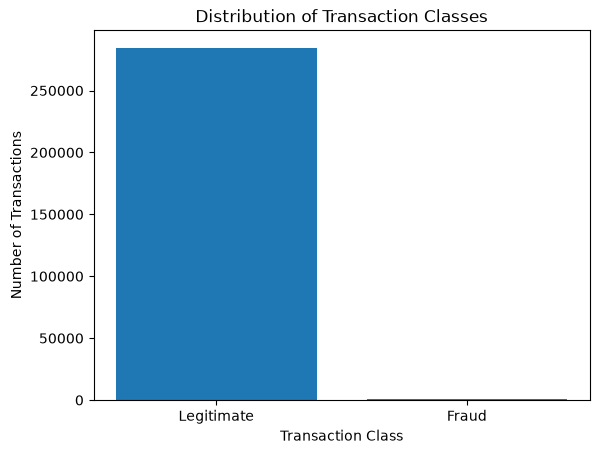

In [21]:
plt.bar(["Legitimate", "Fraud"], class_counts)

plt.title("Distribution of Transaction Classes")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

The first line contains the most important operation:

``plt.bar(["Legitimate", "Fraud"], class_counts)``

We are giving ``plt.bar()`` two pieces of information, the x-axis categories, ``["Legitimate", "Fraud"]``

and the corresponding y-axis values, ``class_counts``, which are, **284315** and **492**

So conceptually we're saying:

                x                    y


          "Legitimate"    →      284315
          "Fraud"         →         492

Matplotlib turns those pairs into bars.

You are barely be able to see the fraud bar. This is not an error. It is actually an excellent representation of the problem.

Consider the ratio: 
$$
\frac{492} {284315}\approx 578
$$

There are approximately **578 legitimate transactions for every fraudulent transaction.**

Therefore, if the legitimate bar were 578 pixels high the fraud bar would be approximately 1 pixel high.

Our visualisation has revealed just how extreme the imbalance really is.

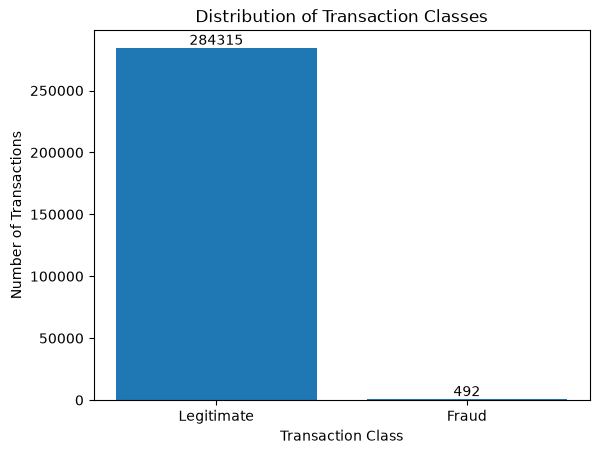

In [22]:
bars = plt.bar(["Legitimate", "Fraud"], class_counts)

plt.title("Distribution of Transaction Classes")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.bar_label(bars)

plt.show()

In [23]:
class_percentages = (
    df["Class"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

class_percentages

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

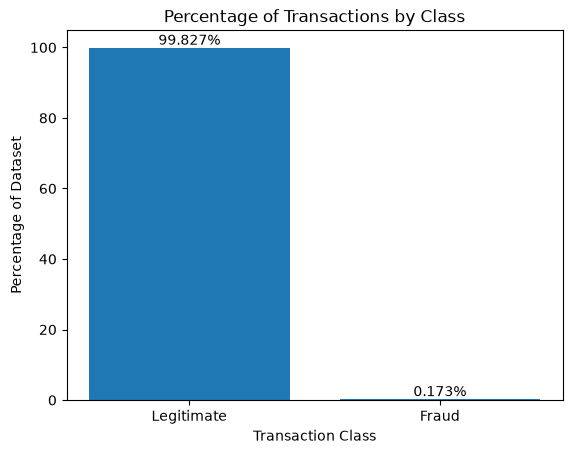

In [24]:
bars = plt.bar(["Legitimate", "Fraud"], class_percentages)

plt.title("Percentage of Transactions by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Percentage of Dataset")

plt.bar_label(bars, fmt="%.3f%%")

plt.show()

The slightly peculiar ``fmt="%.3f%%"``, means roughly, show the value to three decimal places followed by a % sign.

## 18. Why we should NOT "fix" the data yet

Our original dataset represents something close to the real problem:

99.827% legitimate

versus:

0.173% fraud.

If we immediately alter the whole dataset and subsequently split it, our test data will no longer represent that original distribution.

Instead our workflow will be:

ORIGINAL DATA
284,807 transactions
       │
       ▼
Separate features X
from target y
       │
       ▼
TRAIN / TEST SPLIT
       │
       ├─────────────────────┐
       ▼                     ▼
 TRAINING DATA            TEST DATA
       │                     │
       │                     │
resampling/scaling        KEEP ASIDE
when appropriate             │
       │                     │
       ▼                     │
 train model                 │
       │                     │
       └──────────┐          │
                  ▼          ▼
              FINAL EVALUATION

The test set remains untouched by any class-balancing procedure.

That's going to allow us to ask a much more meaningful question:

## 19. How well does our model detect fraud when presented with unseen data having the naturally extreme class imbalance?

We are going to learn **descriptive statistics.**

Our next command will be:

In [25]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


It looks simple, but it will introduce mean, standard deviation, quartiles, minimum and maximum, and we'll connect each of those statistics to the actual transaction data rather than treating describe() as another black-box pandas command.

### What is PCA?

**PCA** stands for **Principal Component Analysis**

At its simplest, **PCA** is a mathematical technique for taking a collection of variables that may contain overlapping information and creating a new set of variables that capture the important patterns in the original data. Let's build the idea visually. Imagine we measured students' height
and arm length. We might get data like:

Arm
length
  ↑
  │                         •
  │                     •
  │                  •
  │              •  •
  │           •
  │       • •
  │    •
  │ •
  └────────────────────────────→ Height

Height and arm length are strongly related. Taller people tend to have longer arms.

That means the two variables contain some overlapping information.

**PCA** essentially asks ***In which direction does this cloud of data vary the most?***

It might find a direction like this:

Arm
length
  ↑
  │                       •
  │                    •
  │                 •
  │              •
  │           •
  │        •
  │     •
  │  •
  └────────────────────────────→ Height
        ↗
       /
      /
 **Principal Component 1**

That new diagonal axis is called a **principal component.**

Instead of describing someone separately by height and arm length, we can describe where they lie along this new axis.

### Why "principal"?

Because **PCA** ranks these new directions according to how much variance they capture.

The first one, ``PC1``captures the greatest possible amount of variation.

The second, ``PC2`` captures the greatest remaining variation while being perpendicular — mathematically orthogonal — to PC1.

Then, ``PC3, PC4,…``, and so on. This gives us a sequence, ``PC1>PC2>PC3>⋯``, in terms of the amount of variance explained.

That does not mean PC1 is necessarily the most useful feature for detecting fraud. It means it explains the greatest variation in the input data.

That's an important distinction.

### What happened to the credit-card data?

We don't know the confidential original variables because the public dataset deliberately doesn't provide them.

But imagine, purely as an illustration, that the bank originally had variables such as, ``x1 =transaction frequency``
``x2 =merchant characteristic``
``x3 =geographic characteristic``
``x4 =account behaviour``
and many others.

Those are hypothetical examples, not descriptions supplied with this dataset.

**PCA** can mathematically combine original variables. A component might have the general form:

PC
1
	​

=a
1
	​

x
1
	​

+a
2
	​

x
2
	​

+a
3
	​

x
3
	​

+⋯+a
n
	​

x
n
	​


where the a's are weights.

For example, in an imaginary three-variable dataset PCA might produce:

PC
1
	​

=0.7x
1
	​

+0.5x
2
	​

−0.2x
3
	​


and:

PC
2
	​

=−0.1x
1
	​

+0.6x
2
	​

+0.8x
3
	​


Those numbers are just illustrative.

The important idea is that a principal component generally isn't simply a renamed original column.

It is a mathematical combination of the original features.

## So what are V1 to V28?

V1–V28 are the PCA-transformed features. The dataset documentation does not tell us what original real-world variables contributed to each one.

## Why use PCA at all?

PCA is commonly useful for dimensionality reduction.

Suppose we originally had:

100 variables

but discovered that most of the meaningful variation could be represented by:

20 principal components.

Then we could potentially replace:

100 dimensions

with:

20 dimensions

while retaining much of the information.

This can reduce redundancy, computational requirements and sometimes noise.

In this particular dataset, however, we should be careful: the source tells us PCA was applied to the original features, but it doesn't give us enough information to reconstruct the original feature set or conclude exactly how much dimensionality reduction occurred. Its privacy/anonymisation role is especially relevant here.

## 20. Exploratory Data Analysis

Before training a machine learning model, I need to understand the numerical
characteristics of the dataset.

Descriptive statistics provide a summary of the distribution, range and
variation of each numerical feature.

In [26]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Rather than trying to understand all 31 columns simultaneously, we'll concentrate first on a variable whose meaning we actually know:

Amount

In [27]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

1. count

This is the number of non-null Amount observations.

2. mean

This is the arithmetic mean:

x
ˉ
=
n
∑
i=1
n
	​

x
i
	​

	​


In simpler terms:

mean=
number of transactions
sum of all transaction amounts
	​


Suppose our transaction amounts were:

10,20,30

Then:

mean=
3
10+20+30
	​

=20

3. std - This means standard deviation.

For now, think of standard deviation as a measure of how spread out the observations are around their mean.

If our data were:

49,50,51

there isn't much variation, so the standard deviation would be small.

Compare that with:

1,50,99

The mean is still 50:

3
1+50+99
	​

=50

but the observations are much more spread out.

Therefore the second dataset has a much larger standard deviation.

We'll return to the mathematics of standard deviation when we reach feature scaling, because it becomes directly relevant to StandardScaler.

## Understanding 25%, 50% and 75%

These are particularly useful, they are quartiles.

Imagine sorting all 284,807 transaction amounts from smallest to largest:

Smallest                                      Largest
   │                                             │
   ▼                                             ▼

   ├───────────┼───────────┼───────────┼─────────┤
              25%         50%         75%
                           ↑
                         median

The 25th percentile means approximately 25% of observations are at or below this value.

The 50th percentile is particularly important:

50% percentile=median
	​


Half the observations lie below it and half above it.

The 75th percentile has approximately 75% of observations at or below it.

## Mean versus median

In [28]:
print("Mean:  ", df["Amount"].mean())
print("Median:", df["Amount"].median())

Mean:   88.34961925093134
Median: 22.0


If the mean is substantially larger than the median, that's telling us something about the distribution.

Consider this imaginary set of transactions:

10,12,15,18,1000

The median is:

15

But the mean is:

5
10+12+15+18+1000
	​

=
5
1055
	​

=211

So:

median=15

but:

mean=211

The £1000 observation has pulled the mean dramatically upwards.

The median is much less affected by that extreme value.

This is one reason why the mean and median together can tell us more than either one alone.

## Visualise Amount

Now let's actually see the distribution.

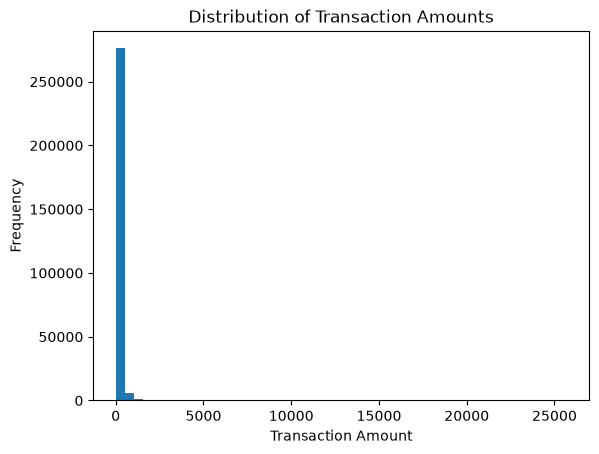

In [29]:
plt.hist(df["Amount"], bins=50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

## What does bins=50 mean?

A histogram doesn't draw one bar for every individual transaction amount.

Instead it divides the numerical range into intervals called bins.

For example, imagine our values ran from 0 to 100:

0       20       40       60       80       100
|--------|--------|--------|--------|---------|
  bin 1    bin 2    bin 3    bin 4    bin 5

Matplotlib counts how many observations fall into each interval.

We're asking for:

bins=50

so it divides the complete Amount range into 50 intervals.

## Don't "fix" a strange-looking histogram

Your histogram may look rather peculiar.

Most observations may appear crowded towards the left-hand side while the x-axis stretches a long way to the right.

That's potentially telling us something real about the data.

We should not immediately remove the large values simply because they make the graph inconvenient.

Instead we investigate.

In [30]:
df.nlargest(10, "Amount")[["Amount", "Class"]]

,Amount,Class
274771,25691.16,0
58465,19656.53,0
151296,18910.00,0
46841,12910.93,0
54018,11898.09,0
169457,11789.84,0
284249,10199.44,0
227921,10000.00,0
74699,8790.26,0
245474,8787.00,0


Break that down:

df.nlargest(10, "Amount")

means:

Give me the 10 rows having the largest values of Amount.

Then:

[["Amount", "Class"]]

means:

From those rows, show me only Amount and Class.

This allows us to investigate whether the very largest transactions are necessarily fraudulent.

Importantly, don't assume that they will be.

## Compare legitimate and fraudulent transactions

Now we can ask pandas to calculate the Amount statistics separately for our two classes:

In [31]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


This is worth breaking down carefully.

df.groupby("Class")

Pandas conceptually separates the DataFrame into:

                    df
                     │
              group by Class
                     │
             ┌───────┴───────┐
             ▼               ▼
         Class = 0        Class = 1
        legitimate          fraud
         284315              492

Then:

["Amount"]

says:

Examine the Amount variable within each group.

Finally:

.describe()

says:

Calculate the descriptive statistics for each group.

So we should get two rows:

Class 0    count mean std min 25% 50% 75% max

Class 1    count mean std min 25% 50% 75% max

This is our first real attempt to ask:

**Do fraudulent transactions differ from legitimate ones?**

## Mean and median by class

We can also make the comparison more explicit.

In [32]:
df.groupby("Class")["Amount"].mean()

Class
0     88.291022
1    122.211321
Name: Amount, dtype: float64

In [33]:
df.groupby("Class")["Amount"].median()

Class
0    22.00
1     9.25
Name: Amount, dtype: float64

We'll compare:

mean amount for legitimate transactions

with:

mean amount for fraudulent transactions

and do the same for the medians.

But we need to be careful with our interpretation.

Even if fraud has a higher or lower average Amount, that does not mean:

Amount causes fraud

It only demonstrates an association in this dataset.

In [34]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

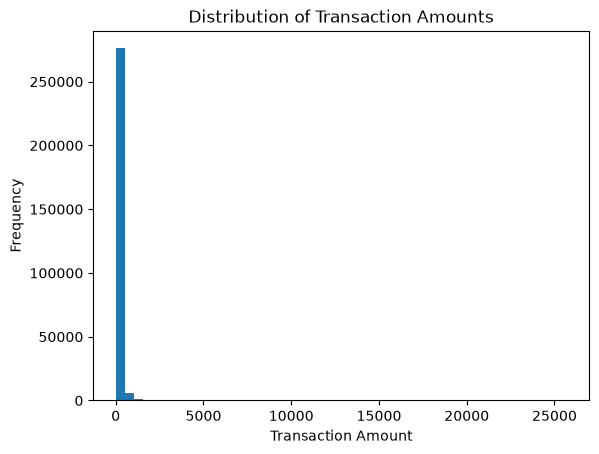

In [35]:
plt.hist(df["Amount"], bins=50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

Here:

df["Amount"] = the data we are turning into a histogram.
bins=50 = divide the range of transaction amounts into 50 intervals.
The x-axis represents transaction amount.
The y-axis represents how many transactions fall within each amount interval.

In [36]:
df.nlargest(10, "Amount")[["Amount", "Class"]]

,Amount,Class
274771,25691.16,0
58465,19656.53,0
151296,18910.00,0
46841,12910.93,0
54018,11898.09,0
169457,11789.84,0
284249,10199.44,0
227921,10000.00,0
74699,8790.26,0
245474,8787.00,0


In [37]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [38]:
df.groupby("Class")["Amount"].median()

Class
0    22.00
1     9.25
Name: Amount, dtype: float64

284,807 individual Amount values

              │
              ├──────────────► df["Amount"].describe()
              │                 numerical summary
              │
              └──────────────► plt.hist(df["Amount"])
                                visual representation
                                of the distribution

## 21. Preparing the Data for Machine Learning

The dataset now needs to be separated into the information that the model
will use to make predictions and the answer that it is trying to predict.

In machine learning these are conventionally represented as:

- X — the input features
- y — the target variable

For this project, `Class` is the target variable.

In [39]:
X = df.drop("Class", axis=1)
y = df["Class"]

## What is X?

X contains the features — everything we're allowing the model to examine when trying to recognise fraud.

That means:

X

│

├── Time

├── V1

├── V2

├── ...

├── V28

└── Amount

There should be 30 columns.

What is y?

y contains only:

Class

which is the correct answer:

0 = legitimate
1 = fraud

So conceptually:

X⟶machine-learning model⟶
y
^
	​


where y is the actual answer and 
y
^
	​
("y-hat") is the model's predicted answer.

## Understanding drop()

This line deserves explanation:

X = df.drop("Class", axis=1)

We're telling pandas:

Make X from df, but remove the Class column.

The important part is:

axis=1

For a DataFrame, think:

axis=0  → rows
axis=1  → columns

Therefore:

df.drop("Class", axis=1)

means:

Drop the Class column.

It does not remove Class from the original df; drop() returns a new DataFrame here, which we store as X.

In [40]:
print("Original dataset:", df.shape)
print("Features X:", X.shape)
print("Target y:", y.shape)

Original dataset: (284807, 31)
Features X: (284807, 30)
Target y: (284807,)


Notice that y doesn't say:

(284807, 1)

It says:

(284807,)

That's because y is a one-dimensional pandas Series, whereas X is a two-dimensional DataFrame.

## The train/test split

Now we reach one of the most important ideas in machine learning.

We do not want to train our model on all 284,807 transactions and then ask it how well it performs on those same transactions.

That would be rather like giving a student the examination paper and answers during revision and then assessing them using exactly the same questions.

Instead:

                  ORIGINAL DATA
                       │
                       ▼
               284,807 transactions
                       │
                ┌──────┴──────┐
                ▼             ▼
             TRAIN           TEST
              80%             20%
                │              │
                ▼              │
          Model learns         │
          from these           │
                │              │
                └──────┐       │
                       ▼       ▼
                  Evaluate model
                  on unseen data

We'll use scikit-learn for this.

In [41]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
from sklearn.model_selection import train_test_split

## Perform the split

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

There are several new ideas here, so we'll unpack them.

test_size=0.20

We're reserving:

20%

of our data for testing.

Approximately:

80%

remains for training.

random_state=42

The rows need to be randomly allocated.

If we simply did that afresh every time we ran the notebook, we'd get slightly different training and test datasets every time.

random_state=42 fixes the random-number sequence, making our experiment reproducible.

There is nothing mathematically special about 42. We could have used:

random_state=7

or:

random_state=123

The important thing is that we fix it.

stratify=y

This one is particularly important for our dataset.

Remember:

99.827% legitimate

and:

0.173% fraud

We want both training and testing sets to preserve approximately that class distribution.

stratify=y tells scikit-learn:

When splitting the data, maintain approximately the same proportions of Class=0 and Class=1.

With only 492 fraud cases, this is a sensible precaution.

## Inspect what we've created

In [44]:
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (227845, 30)
X_test:  (56962, 30)
y_train: (227845,)
y_test:  (56962,)


So the model will learn from approximately 228,000 transactions, while approximately 57,000 transactions are being held back.

## Prove stratification worked

In [45]:
print("Original:")
print(y.value_counts(normalize=True) * 100)

print("\nTraining:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting:")
print(y_test.value_counts(normalize=True) * 100)

Original:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Training:
Class
0    99.827075
1     0.172925
Name: proportion, dtype: float64

Testing:
Class
0    99.827955
1     0.172045
Name: proportion, dtype: float64


The fraud percentages all remain very close to:

0.173%

That's evidence that stratify=y has done what we intended.

And now we establish a very important rule

From this point onward:

We do not use X
test
	​

 or y
test
	​

 to train the model.
	​


Think of them as being placed in a sealed envelope.

X_train + y_train

       │
       ▼
       
 preprocessing
 balancing
 training
 tuning
 cross-validation
 
       │
       ▼
       
    MODEL
       │
       │
       ▼
       
X_test + y_test  ← finally open the envelope
       │
       ▼
       
Final evaluation

This protects us against data leakage and overly optimistic evaluation.

What comes immediately after this

Once you've completed the split, we'll move to feature scaling with StandardScaler. That's where the standard deviation we just discussed becomes directly relevant.

We'll derive what scaling actually does:

z=
σ
x−μ
	​


rather than simply writing:

StandardScaler()

and treating it as magic.

And importantly, we'll fit the scaler only on X_train, not on the complete dataset. That distinction is one of the reasons we made the train/test split before preprocessing.

we’ll fit the scaler only on the training data to avoid leaking information from the test set.

## What does scaling mean?

Different features can live on very different numerical scales.

For example, imagine:

Feature A:  0.2, 0.7, 1.1, 0.5

Feature B:  15, 300, 2500, 80

A machine-learning algorithm may be affected by those differences in magnitude.

Standard scaling transforms a value using:

z=
σ
x−μ
	​


where:

x=original value
μ=mean of the training feature
σ=standard deviation of the training feature

and:

z=scaled value

The result is a feature centred around approximately:

μ≈0

with standard deviation approximately:

σ≈1

A simple numerical example

Suppose a feature has:

μ=100

and:

σ=20

For:

x=140

we calculate:

z=
20
140−100
	​

z=
20
40
	​

z=2
	​


That means the original value is:

2 standard deviations above the mean.

If instead:

x=80

then:

z=
20
80−100
	​

=−1

So that value lies:

1 standard deviation below the mean.

This is what StandardScaler will do automatically.

## Feature Scaling

Some features are measured on different numerical scales.

Standardisation transforms a feature according to:

$$
z = \frac{x-\mu}{\sigma}
$$

where $\mu$ is the mean and $\sigma$ is the standard deviation.

The scaler will be fitted only on the training data so that information
from the test data does not influence preprocessing.

In [46]:
from sklearn.preprocessing import StandardScaler

## Create the scaler

In [47]:
scaler = StandardScaler()

Nothing visible happens.

We have simply created a StandardScaler object and stored it in:

scaler

At this point it has not learned anything yet.

That distinction is important.

## fit() versus transform()

There are two separate ideas.

fit()

When the scaler is fitted, it learns the training-data statistics:

μ

and:

σ

for each feature.

transform()

Once those values have been learned, the scaler applies:

z=
σ
x−μ
	​


to each observation.

So:

fit
 ↓
learn mean and standard deviation

transform
 ↓
use those values to scale the data

Scikit-learn also gives us:

fit_transform()

which performs both operations in one step.

Make copies first

I recommend that we preserve the original X_train and X_test.

Create:

In [48]:
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

Now we can experiment without overwriting our original data.

This is a good habit in exploratory work.

## Scale Time and Amount

We'll start by scaling only the two named variables:

In [49]:
features_to_scale = ["Time", "Amount"]

In [50]:
X_train_scaled[features_to_scale] = scaler.fit_transform(
    X_train[features_to_scale]
)

In [51]:
X_test_scaled[features_to_scale] = scaler.transform(
    X_test[features_to_scale]
)

Notice the crucial difference:

Training:

fit_transform()

Test:

transform()

We do not write:

scaler.fit_transform(X_test[features_to_scale])

because that would allow the test set to calculate its own mean and standard deviation.

That would contaminate our evaluation.

## Why fitting on the test set is leakage

Suppose our test set has unusually large transactions.

If we calculate the test-set mean before evaluating the model, then information about those supposedly unseen transactions has influenced our preprocessing.

Conceptually, that's like saying:

TEST SET
   │
   ├── tell us your mean
   ├── tell us your standard deviation
   │
   ▼
preprocessing

But our rule is:

The test set should not teach us anything.
	​


Instead:

TRAINING SET
     │
     ├── calculate μ
     ├── calculate σ
     │
     ▼
   scaler
     │
     ├──────────────► scale training data
     │
     └──────────────► scale test data
                       using TRAINING μ and σ

That is the correct workflow.

## Check what happened

In [52]:
X_train_scaled[["Time", "Amount"]].describe()

,Time,Amount
count,2.278450e+05,2.278450e+05
mean,-1.409578e-16,3.742243e-17
std,1.000002e+00,1.000002e+00
min,-1.998073e+00,-3.516894e-01
25%,-8.561495e-01,-3.291944e-01
50%,-2.122647e-01,-2.639429e-01
75%,9.366285e-01,-4.262209e-02
max,1.640549e+00,1.021170e+02


In [53]:
X_train[["Time", "Amount"]].describe()

,Time,Amount
count,227845.000000,227845.000000
mean,94885.093704,88.176298
std,47488.415034,250.722602
min,0.000000,0.000000
25%,54228.000000,5.640000
50%,84805.000000,22.000000
75%,139364.000000,77.490000
max,172792.000000,25691.160000


Pay particular attention to:

mean
std

For the scaled training variables, you should see values very close to:

mean ≈ 0
std  ≈ 1

The mean may look something like:

2.1e-16

or:

-3.7e-17

That is effectively zero.

It appears because floating-point arithmetic is not infinitely precise.

The mean is essentially zero

You have:

Time      -1.409578e-16
Amount     3.742243e-17

Scientific notation makes these look more significant than they are.

For example:

−1.409578×10
−16

means approximately:

−0.0000000000000001409578

For our purposes:

mean≈0
	​


The tiny discrepancy is simply normal floating-point precision.

The standard deviation is essentially 1

You have:

Time      1.000002
Amount    1.000002

So:

σ≈1
	​


Exactly what we wanted.

There is a tiny technical reason pandas shows 1.000002 rather than exactly 1.000000: StandardScaler and pandas' describe() use slightly different conventions for calculating variance/standard deviation. With 227,845 observations, the difference is negligible. 

But look at Amount maximum

This is particularly interesting:

Amount max = 1.021170e+02

That's:

102.117

standard deviations above the mean.

That looks enormous — and it is.

It confirms what we saw earlier: transaction Amount is strongly right-skewed with some extreme values.

Notice something important here:

standardisation does not remove outliers
	​


It simply expresses their position relative to the training mean and standard deviation.

For comparison, your scaled Time ranges roughly from:

−2.00to+1.64

whereas Amount reaches:

+102.12

So the two distributions remain very different even though both now have:

μ≈0,σ≈1

## Compare before and after

You should see that the original values might have:

Time:
mean = large number
std  = large number


Amount:
mean = around tens/hundreds
std  = much larger

while the scaled versions have:

mean ≈ 0
std  ≈ 1

The relative structure of the data has changed in scale, but not in ordering.

## What scaling does NOT mean

Scaling does not mean:

all features become equally important.

It means:

their numerical scales become more comparable.

The machine-learning model still decides which features are useful.

And scaling does not change:

fraud → legitimate

or:

small transaction → large transaction

It simply changes the numerical representation.

For example:

£10
£50
£500

might become something like:

-0.6
-0.4
 1.8

The ordering is still preserved.

## Why only Time and Amount?

For this particular dataset, the PCA-derived variables V1–V28 were already transformed before publication. We therefore focused standardisation on Time and Amount.

For our first model, we'll follow that choice.

Later, when we work with other datasets, we may need to scale many or all numerical features ourselves.

## Your scaling code together

Your executable section should now look like this:

from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()


X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()


features_to_scale = ["Time", "Amount"]


X_train_scaled[features_to_scale] = scaler.fit_transform(
    X_train[features_to_scale]
)


X_test_scaled[features_to_scale] = scaler.transform(
    X_test[features_to_scale]
)

Then verify it:

X_train_scaled[["Time", "Amount"]].describe()

Once that gives mean values close to 0 and standard deviations close to 1, the next step is our first genuine classifier: Logistic Regression. That will let us connect the code to the sigmoid equation rather than treating LogisticRegression() as a black box.

## 9. Logistic Regression

The first machine learning model I will investigate is Logistic Regression.

Despite its name, Logistic Regression is commonly used for classification.
In this project the model will attempt to estimate the probability that a
transaction belongs to the fraudulent class.

The model will be trained using the training data and subsequently evaluated
using data that it has not seen during training.

**Why is it called Logistic Regression?**

Suppose we tried to construct a simple linear equation:

z=$b_0 +b_1x_1+b_2x_2+⋯+b_nx_n$


Here:$x_1,x_2,…,x_n$  are our features — **Time, V1, V2, ..., Amount.**

The b's are numbers the model learns during training: $b_0 =intercept$

and $b_1,b_2,…,b_n =coefficients$

The problem is that z could have any value:

−∞<z<+∞

We want something interpretable as a probability:

0≤P≤1.

So Logistic Regression passes z through another mathematical function.

That function is the ***sigmoid, or logistic, function**:

P(y=1)=
1+e
−z
1
	​

	​


This has a very useful property:

z very negative  → probability approaches 0


z = 0            → probability = 0.5


z very positive  → probability approaches 1

For example, when:

z=0

we get:

P=
1+e
0
1
	​


Since:

e
0
=1

then:

P=
2
1
	​

=0.5.

So the model essentially performs:

Features→weighted combination z→sigmoid→probability
	​


For our fraud problem:

P(y=1)

means the model's estimated probability that the transaction belongs to Class 1 — fraud.

That's the conceptual foundation.

### The sigmoid function

Logistic Regression first calculates a weighted combination of the input
features:

$$
z = b_0 + b_1x_1 + b_2x_2 + \cdots + b_nx_n
$$

The value of $z$ can range from negative infinity to positive infinity.

To convert this into a value between 0 and 1, Logistic Regression uses the
sigmoid function:

$$
P(y=1) = \frac{1}{1+e^{-z}}
$$

The resulting value can be interpreted as the model's estimated probability
that an observation belongs to Class 1.

## What is e?

In:

1+e
−z
1
	​


the e is a mathematical constant:

e≈2.71828

It plays a fundamental role in exponential growth, logarithms and calculus. We don't need to explore all of that here, but later Logistic Regression will lead naturally into logarithms and the log-odds, which will explain why the model has the name logistic regression.

For now we need Python to calculate exponentials.

In [54]:
import numpy as np

In [55]:
np.exp(1)

np.float64(2.718281828459045)

because:

e1 =e.

In [56]:
np.exp(0)

np.float64(1.0)

which gives:

e0 =1.

## Write the sigmoid ourselves

In [57]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

This is a Python function.

def sigmoid(z):

means:

Define a function called sigmoid which receives a value called z.

Then:

return 1 / (1 + np.exp(-z))

is almost a direct translation of:

1+e
−z
1
	​


because:

np.exp(-z)

means:

e−z
.

## Test some values

In [58]:
print("z = -5:", sigmoid(-5))
print("z =  0:", sigmoid(0))
print("z =  5:", sigmoid(5))

z = -5: 0.0066928509242848554
z =  0: 0.5
z =  5: 0.9933071490757153


When:

z=−5

the probability is very close to:

0

When:

z=0

the probability is exactly:

0.5

When:

z=5

the probability is very close to:

1.

Notice that even though z went from:

−5→+5,

the sigmoid output remained trapped within:

0<P<1.

That's exactly what we need for a probability.

## Plot the sigmoid

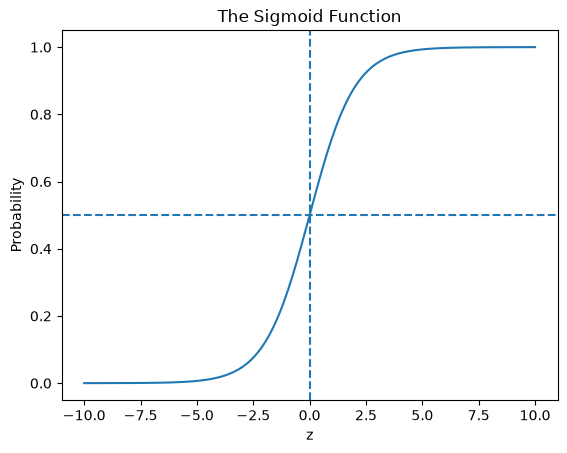

In [59]:
z = np.linspace(-10, 10, 200)

probability = sigmoid(z)

plt.plot(z, probability)

plt.title("The Sigmoid Function")
plt.xlabel("z")
plt.ylabel("Probability")

plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")

plt.show()

The important point is in the centre:

z=0

corresponds to:

P=0.5.

The curve then approaches 0 and 1 but never actually passes outside those limits.

## What does np.linspace() do?

This line:

z = np.linspace(-10, 10, 200)

means:

Generate 200 evenly spaced numbers between -10 and +10.

So NumPy produces something conceptually like:

-10.0
 -9.9
 -9.8
 ...
  0.0
 ...
  9.8
  9.9
 10.0

We then pass all 200 values through:

sigmoid(z)

NumPy allows our function to operate over the whole array.

That's what gives Matplotlib enough points to draw a smooth curve.

## From probability to classification

Now we can see how this eventually becomes a binary decision.

A common default threshold is:

0.5.

Conceptually:

P(y=1)<0.5⇒
y
^
	​

=0

and:

P(y=1)≥0.5⇒
y
^
	​

=1.

For our project:

Probability
     │
     ▼

0 ───────────── 0.5 ───────────── 1
      │                       │
      ▼                       ▼
 Legitimate                 Fraud
 Class 0                    Class 1

But here's something very important that we'll revisit later:

0.5 is not necessarily the best threshold for fraud detection.
	​


Imagine two transactions receive:

Transaction A → fraud probability 0.49
Transaction B → fraud probability 0.51

At a 0.5 threshold:

A → legitimate
B → fraud

Yet the model's assessment of the two transactions is actually very similar.

And because missing genuine fraud may have a very different cost from temporarily flagging a legitimate transaction, threshold choice becomes an important practical decision.

That will lead us naturally to precision, recall, ROC curves and eventually precision-recall curves.

## Now create the actual Logistic Regression model

In [60]:
from sklearn.linear_model import LogisticRegression

In [61]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

At this point we've created the model, but we have not trained it.

The learning happens when we execute:

logistic_model.fit(X_train_scaled, y_train)

Here:

X_train_scaled  → the evidence
y_train         → the known correct answers

So the model receives approximately 228,000 examples for which we already know whether the transaction was legitimate or fraudulent.

During .fit(), Logistic Regression learns the coefficients:

b
0
	​

,b
1
	​

,b
2
	​

,…,b
30
	​


that best relate our 30 features to the target.

In [62]:
logistic_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

### Examining a single prediction

Before evaluating the model across the complete test dataset, I will examine
how it handles a single unseen transaction.

For this transaction I will compare:

- the actual class
- the probability predicted by the model
- the final class predicted by the model

In [63]:
single_transaction = X_test_scaled.iloc[[0]]

single_transaction

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
263020,1.387182,-0.674466,1.408105,-1.110622,-1.328366,1.388996,-1.308439,1.885879,-0.614233,0.311652,...,0.394322,0.080084,0.810034,-0.224327,0.707899,-0.135837,0.045102,0.533837,0.291319,-0.259954


## What does .iloc[[0]] mean?

iloc selects data according to its integer position.

So:

X_test_scaled.iloc[[0]]

means:

Give me the first row of X_test_scaled.

There is a subtle reason I've used:

[[0]]

rather than:

[0]

Using the double brackets keeps the result as a two-dimensional DataFrame:

1 transaction × 30 features

That's the shape scikit-learn expects for prediction.

## What was the real answer?

We deliberately kept the answers separately in:

y_test

So let's find the actual class of this transaction:

actual_class = y_test.iloc[0]


print("Actual class:", actual_class)

You'll probably get 0, simply because legitimate transactions massively outnumber frauds.

Remember:

0 = legitimate
1 = fraud

At this point we're effectively the examiner holding the answer sheet.

In [64]:
actual_class = y_test.iloc[0]

print("Actual class:", actual_class)

Actual class: 0


## Ask the model for a prediction

In [65]:
predicted_class = logistic_model.predict(single_transaction)

print("Predicted class:", predicted_class[0])

Predicted class: 0


You should get either:

Predicted class: 0

or:

Predicted class: 1

This is the model's final classification.

But this hides something interesting.

The model didn't internally think simply:

"0."

It calculated probabilities first.

Let's look at them.

## Ask for probabilities

In [66]:
predicted_probabilities = logistic_model.predict_proba(single_transaction)

predicted_probabilities

array([[9.99909656e-01, 9.03437762e-05]])

These two numbers mean:

first number  = estimated probability of Class 0
second number = estimated probability of Class 1

Therefore:

P(y=0)+P(y=1)=1

For this project:

P(Class 0) = probability of legitimate


P(Class 1) = probability of fraud

Let's make that easier to read:

In [67]:
prob_legitimate = predicted_probabilities[0][0]
prob_fraud = predicted_probabilities[0][1]

print(f"Probability legitimate: {prob_legitimate:.6%}")
print(f"Probability fraud:      {prob_fraud:.6%}")

Probability legitimate: 99.990966%
Probability fraud:      0.009034%


**Connect this to our sigmoid**

**This is where everything we've just learned comes together.**
The transaction contains:
\[
x_1,x_2,x_3,\ldots,x_{30}
\]Our trained Logistic Regression model has learned:
\[
b_0,b_1,b_2,\ldots,b_{30}
\]It calculates:
\[
z=b_0+b_1x_1+b_2x_2+\cdots+b_{30}x_{30}
\]and then:
\[
P(y=1)=\frac{1}{1+e^{-z}}
\]That gives the fraud probability.
Then, using the default decision threshold of approximately \(0.5\):
\[
P(y=1)<0.5
\Rightarrow
\hat y=0
\]or:
\[
P(y=1)\geq0.5
\Rightarrow
\hat y=1.
\]So predict() and predict_proba() are giving us two different views:

30 transaction features
          │
          ▼
 Logistic Regression
          │
          ▼
     calculate z
          │
          ▼
       sigmoid
          │
          ▼
    P(fraud) = ?
          │
          ├──────────────► predict_proba()
          │                 probability
          │
          ▼
     apply threshold
          │
          ▼
       0 or 1
          │
          └──────────────► predict()
                            class

**Find an actual fraud case**

Because fraud is so rare, your first test transaction is very likely legitimate. It would be much more interesting to deliberately find a fraudulent transaction in our test set.

In [68]:
fraud_positions = np.where(y_test.to_numpy() == 1)[0]

fraud_positions[:10]

array([ 840, 1146, 3287, 4276, 5077, 5453, 7164, 7299, 7337, 9036])

This finds the positions in y_test where:
\[
y=1.
\]Now take the first one:

In [69]:
fraud_position = fraud_positions[0]

fraud_transaction = X_test_scaled.iloc[[fraud_position]]
actual_fraud_class = y_test.iloc[fraud_position]

print("Position:", fraud_position)
print("Actual class:", actual_fraud_class)

Position: 840
Actual class: 1


We now know the actual answer should be:
Actual class: 1

In [70]:
fraud_prediction = logistic_model.predict(fraud_transaction)
fraud_probability = logistic_model.predict_proba(fraud_transaction)

print("Actual class:   ", actual_fraud_class)
print("Predicted class:", fraud_prediction[0])
print(f"Fraud probability: {fraud_probability[0][1]:.6%}")

Actual class:    1
Predicted class: 1
Fraud probability: 71.674659%


So for this particular unseen fraudulent transaction, the model assigned:
\[
P(\text{fraud})=0.71674659
\]or about:
\[
\boxed{71.7\%}
\]Because that is above the default \(0.5\) threshold, the model classified the transaction as fraud:
\[
0.7167 > 0.5
\quad\Rightarrow\quad
\hat y=1
\]And because the actual class was also 1, this is a True Positive (TP).

### Evaluating the model on the complete test set

The model successfully identified the individual fraudulent transaction
examined above. However, a single correct prediction does not provide
sufficient evidence of overall model performance.

I will therefore use the trained model to predict the class of every
transaction in the previously unseen test dataset.

In [71]:
y_pred = logistic_model.predict(X_test_scaled)

This is doing exactly what we did for our single transaction, except now we're passing in the entire test DataFrame:
\[
56,962\text{ transactions}
\]and receiving:
\[
56,962\text{ predictions}.
\]Check that:

In [72]:
print("Number of test transactions:", len(y_test))
print("Number of predictions:      ", len(y_pred))

Number of test transactions: 56962
Number of predictions:       56962


**The numbers match!**

**Construct the confusion matrix**

Now import:

In [73]:
from sklearn.metrics import confusion_matrix

In [74]:
cm = confusion_matrix(y_test, y_pred)

cm

array([[56851,    13],
       [   35,    63]])

**Extract the four numbers**

In [75]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives: ", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives: ", tp)

True Negatives:  56851
False Positives: 13
False Negatives: 35
True Positives:  63


.ravel() takes:
[[TN, FP],
 [FN, TP]]
and flattens it into:
TN, FP, FN, TP
so we can store each value separately.

Calculate accuracy ourselves
Now that we have the four numbers, let's not ask scikit-learn for accuracy yet.
We already know:
\[
Accuracy=
\frac{TP+TN}
{TP+TN+FP+FN}
\]So calculate it ourselves:

In [76]:
accuracy = (tp + tn) / (tp + tn + fp + fn)

print(f"Accuracy: {accuracy:.4%}")

Accuracy: 99.9157%


I expect it to be extremely high.
But remember our deliberately useless baseline:
\[
99.8273\%.
\]Therefore, merely seeing something such as:
99.9% accuracy

should no longer automatically impress us.
The real question is:
**How many of the fraudulent transactions did the model actually find?**

Recall
This introduces one of our most important metrics:
\[
\boxed{
Recall=\frac{TP}{TP+FN}
}
\]Think about the denominator:
\[
TP+FN
\]These are all the transactions that actually were fraudulent.
We're therefore asking:
Of all the fraud that really occurred, what proportion did the model catch?

Calculate it:

In [77]:
recall = tp / (tp + fn)

print(f"Fraud recall: {recall:.4%}")

Fraud recall: 64.2857%


Suppose, purely as an example, our test set contained 98 fraudulent transactions and the model found 60:
\[
Recall=\frac{60}{98}
\]\[
=61.2\%.
\]That would mean:
The model detected about 61% of the fraud but missed about 39%.

**That's much more informative than simply saying the model achieved 99.x% accuracy.**

Precision
Now ask a different question.
Of all the transactions that the model claimed were fraud, how many actually were?
That's:
\[
\boxed{
Precision=\frac{TP}{TP+FP}
}
\]Calculate:

In [78]:
precision = tp / (tp + fp)

print(f"Fraud precision: {precision:.4%}")

Fraud precision: 82.8947%


Why precision and recall can conflict
Suppose we lower our classification threshold from:
\[
0.5
\]to:
\[
0.2.
\]The model becomes more suspicious:
"Even a 20% fraud probability is enough for me to flag this transaction."

We would probably detect more actual fraud.
So recall could increase.
But we'd probably also flag more legitimate transactions.
So precision could decrease.
Conversely, raising the threshold to:
\[
0.9
\]makes the model very cautious about declaring fraud.
We may get fewer false alarms, but miss more actual fraud.
So there is often a trade-off:
\[
\boxed{\text{Precision}\longleftrightarrow\text{Recall}}
\]There isn't necessarily one universally "correct" threshold. The appropriate choice depends partly on the real-world costs of the two kinds of mistake.

**F1 score comes after this**
Once we know your actual precision and recall, we'll introduce:
\[
F1=
2\times
\frac{\text{Precision}\times\text{Recall}}
{\text{Precision}+\text{Recall}}
\]But I don't want to pile another metric on before we've interpreted the first two.

In [79]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[56851,    13],
       [   35,    63]])

In [80]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives: ", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives: ", tp)

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)

print()
print(f"Accuracy:  {accuracy:.4%}")
print(f"Precision: {precision:.4%}")
print(f"Recall:    {recall:.4%}")

True Negatives:  56851
False Positives: 13
False Negatives: 35
True Positives:  63

Accuracy:  99.9157%
Precision: 82.8947%
Recall:    64.2857%


Interpret the confusion matrix
First, check the totals.
The actual legitimate transactions were:
\[
TN+FP=56851+13=56864
\]The actual fraudulent transactions were:
\[
TP+FN=63+35=98
\]and:
\[
56864+98=56962
\]which is exactly the size of our test set. Everything is consistent.
We can represent the result as:
	Predicted legitimate	Predicted fraud	Total
Actually legitimate	56,851	13	56,864
Actually fraud	35	63	98
Total	56,886	76	56,962


This table is worth including in your notes because it makes the performance much easier to understand.

What does 99.9157% accuracy really tell us?
Our model correctly classified:
\[
56851+63=56914
\]transactions.
Therefore:
\[
Accuracy=
\frac{56914}{56962}
=99.9157\%
\]That sounds excellent.
But earlier we established that a model which simply predicts legitimate every single time would already achieve approximately:
\[
99.8273\%.
\]So the improvement in overall accuracy is only:
\[
99.9157-99.8273
\approx0.0884
\]percentage points.
Yet our Logistic Regression model is clearly much more useful than the naive model because it actually detects fraud.
This beautifully demonstrates why accuracy is misleading for an imbalanced dataset.

Precision: 82.89%
You obtained:
\[
Precision=
\frac{TP}{TP+FP}
\]Therefore:
\[
Precision=
\frac{63}{63+13}
\]\[
=\frac{63}{76}
\]\[
=\boxed{82.89\%}
\]In plain English:
Of the 76 transactions the model flagged as fraudulent, 63 actually were fraudulent.

So approximately 83 out of every 100 fraud alerts from this model would be genuine, at this particular threshold and on this test set.
Only 13 legitimate transactions were incorrectly flagged.
That's a fairly low false-alarm count.

Recall: 64.29%
Now look at the problem from the opposite direction:
\[
Recall=
\frac{TP}{TP+FN}
\]Therefore:
\[
Recall=
\frac{63}{63+35}
\]\[
=\frac{63}{98}
\]\[
=\boxed{64.29\%}
\]In plain English:
Of the 98 fraudulent transactions that actually occurred, the model detected 63.

But it missed:
\[
35
\]of them.
That's:
\[
\frac{35}{98}\times100
\approx35.71\%.
\]So another perfectly legitimate way of describing our model is:
It failed to detect approximately 36% of the fraud in the test set.

Suddenly 99.9157% accuracy doesn't sound quite so extraordinary.
This is precisely why we are examining several metrics.

**Precision versus recall**
Our model currently behaves rather like a cautious fraud detector.
It doesn't flag many transactions:
\[
76\text{ out of }56962.
\]When it does flag one, it's usually correct:
\[
82.89\%\text{ precision}.
\]But that caution comes at a cost:
\[
35\text{ of 98 frauds were missed}.
\]So we have:

This is much more informative than:
"Our model has 99.9% accuracy."

## F1 score
Now we're ready for the metric we deliberately postponed.
Precision asks:
When I predict fraud, how often am I right?

Recall asks:
Of all the actual fraud, how much do I find?

The F1 score combines the two:
\[
F1=
2\frac{Precision\times Recall}
{Precision+Recall}
\]Using our results:
\[
Precision=0.828947
\]and:
\[
Recall=0.642857
\]so:
\[
F1=
2\frac{0.828947\times0.642857}
{0.828947+0.642857}
\]which is approximately:
\[
\boxed{0.7241}
\]or:
\[
\boxed{72.41\%}
\]Let's verify that with Python rather than taking my calculation on trust.
Add:

In [81]:
f1 = 2 * (precision * recall) / (precision + recall)

print(f"F1 score: {f1:.4%}")

F1 score: 72.4138%


In [82]:
from sklearn.metrics import f1_score

print(f"Scikit-learn F1: {f1_score(y_test, y_pred):.4%}")

Scikit-learn F1: 72.4138%


**The two agree**

**Why isn't F1 just the ordinary average?**
You might reasonably wonder why we don't simply calculate:
\[
\frac{Precision+Recall}{2}.
\]F1 uses the harmonic mean, rather than the arithmetic mean.
That makes it more sensitive when one of the two values is poor.
For example, imagine:
\[
Precision=100\%
\]but:
\[
Recall=10\%.
\]The ordinary arithmetic mean would be:
\[
\frac{100+10}{2}=55\%.
\]But the F1 score would be only:
\[
F1=
2\frac{1.0\times0.1}{1.0+0.1}
\approx18.18\%.
\]That better reflects the fact that a fraud detector finding only 10% of fraud has a serious weakness despite its perfect precision.

## Let scikit-learn produce the full report
Now run:

In [83]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



You'll recognise precision, recall and F1, but two new ideas appear:
**support**
This simply means:
How many actual observations belonged to this class?

**macro avg versus weighted avg**
This is particularly important with our imbalanced data.
Macro average gives each class equal importance:
\[
\frac{\text{metric for Class 0}+
\text{metric for Class 1}}{2}
\]regardless of the fact that one class contains 56,864 observations and the other only 98.
Weighted average takes the class sizes into account.
Because legitimate transactions dominate our dataset, the weighted averages can look extremely impressive even when fraud detection is substantially weaker.
That is another consequence of class imbalance.

## The classification threshold
At present, Logistic Regression is effectively making this decision:
\[
P(\text{fraud}) < 0.5 \Rightarrow \text{Class 0}
\]\[
P(\text{fraud}) \geq 0.5 \Rightarrow \text{Class 1}
\]But 0.5 is a decision threshold, not a law of nature.
Suppose the model produces these probabilities:
Transaction	Fraud probability	At threshold 0.5
A	0.03	Legitimate
B	0.18	Legitimate
C	0.42	Legitimate
D	0.51	Fraud
E	0.91	Fraud


Transaction C is particularly interesting. The model thinks there is a 42% probability of fraud, but because:
\[
0.42 < 0.5
\]it is classified as legitimate.
If we changed our threshold to:
\[
0.3
\]Transaction C would instead be flagged as fraud.
That should help us catch more fraud — but it will probably create more false alarms too.

### Investigating the classification threshold

Logistic Regression produces probabilities before converting them into
class predictions.

The default classification threshold is 0.5. However, changing this threshold
changes the balance between detecting fraudulent transactions and incorrectly
flagging legitimate transactions.

I will investigate how different thresholds affect precision and recall.

In [84]:
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

predict_proba() produces two probabilities for every transaction:
                    Class 0     Class 1
Transaction 1       0.998       0.002
Transaction 2       0.140       0.860
Transaction 3       0.650       0.350
...
We only want the probability of:
\[
\text{Class 1}=\text{fraud}.
\]In NumPy notation:
[:, 1]
means:
Select every row (:), but only column 1.

Remember Python counts from zero:
column 0 → probability of Class 0
column 1 → probability of Class 1
So y_prob now contains one fraud probability for each of our 56,962 test transactions.
Check it:

In [85]:
print(len(y_prob))
print(y_prob[:10])

56962
[9.03437762e-05 3.10843634e-05 7.56699117e-06 1.29796056e-04
 8.13763870e-03 2.77629729e-04 2.97562379e-05 1.57076833e-04
 7.92567723e-04 2.18695528e-05]


## Recreate the 0.5 predictions ourselves
Before changing the threshold, let's prove that we understand what predict() was doing.
Create:

In [86]:
y_pred_05 = (y_prob >= 0.5).astype(int)

In [87]:
np.array_equal(y_pred, y_pred_05)

True

we've demonstrated that our manually applied 0.5 threshold reproduces the model's predict() result.

## Lower the threshold to 0.3
Now let's deliberately change the model's decision rule:

In [88]:
y_pred_03 = (y_prob >= 0.3).astype(int)

Notice that we have not retrained the model.
Nothing about:
logistic_model
has changed.
The model still produces exactly the same probabilities.
We have changed only the rule used to turn those probabilities into 0 or 1.
Now calculate the confusion matrix:

In [89]:
cm_03 = confusion_matrix(y_test, y_pred_03)

tn_03, fp_03, fn_03, tp_03 = cm_03.ravel()

print("True Negatives: ", tn_03)
print("False Positives:", fp_03)
print("False Negatives:", fn_03)
print("True Positives: ", tp_03)

True Negatives:  56839
False Positives: 25
False Negatives: 31
True Positives:  67


I expect two particularly important changes:
\[
TP\uparrow
\]and probably:
\[
FP\uparrow.
\]In words:
We should catch more fraud, but probably generate more false alarms.

Let's see what your actual data say rather than assuming.

## Calculate precision and recall at 0.3
Instead of calculating them manually every time, we can now use scikit-learn:

In [90]:
from sklearn.metrics import precision_score, recall_score

In [91]:
precision_03 = precision_score(y_test, y_pred_03)
recall_03 = recall_score(y_test, y_pred_03)

print(f"Precision at 0.3: {precision_03:.4%}")
print(f"Recall at 0.3:    {recall_03:.4%}")

Precision at 0.3: 72.8261%
Recall at 0.3:    68.3673%


Our original values at 0.5 were:
\[
Precision=82.89\%
\]\[
Recall=64.29\%.
\]Now we'll see what moving to 0.3 actually costs and gains.

## Don't test thresholds one at a time
We could manually repeat this for:
\[
0.4,\quad0.3,\quad0.2,\quad0.1
\]but that's exactly the kind of repetitive work Python is designed to eliminate.
Let's use a loop:

In [92]:
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.4%} | "
        f"Recall: {recall:.4%}"
    )

Threshold: 0.5 | Precision: 82.8947% | Recall: 64.2857%
Threshold: 0.4 | Precision: 80.2469% | Recall: 66.3265%
Threshold: 0.3 | Precision: 72.8261% | Recall: 68.3673%
Threshold: 0.2 | Precision: 73.7374% | Recall: 74.4898%
Threshold: 0.1 | Precision: 70.0935% | Recall: 76.5306%


**What I want you to look for**
Don't worry initially about which threshold is "best."
Look for the pattern.
As the threshold moves:
\[
0.5\rightarrow0.4\rightarrow0.3\rightarrow0.2\rightarrow0.1
\]we're making it progressively easier for a transaction to be classified as fraud.
So conceptually:

This is the beginning of understanding the precision–recall trade-off.
And it raises a much deeper question:
\[
\boxed{\text{What threshold should we actually choose?}}
\]We shouldn't simply choose the threshold that produces the nicest-looking number.
For a fraud-detection system, the decision would depend on the relative consequences of:
\[
\text{False Negative}
\]versus:
\[
\text{False Positive}.
\]Missing a £10,000 fraudulent transaction may be considerably more costly than temporarily flagging a legitimate £20 purchase — but excessive false alarms also inconvenience customers and cost money to investigate.
That means model evaluation eventually becomes a decision problem, not merely a mathematical one.
Run the threshold loop in Stage 89 and show me the five lines it produces. We'll examine the pattern together before introducing the precision-recall curve.

lowering the classification threshold increases fraud detection, but reduces precision.

In [93]:
Here are your actual results:
Threshold	Precision	Recall
0.5	82.89%	64.29%
0.4	80.25%	66.33%
0.3	72.83%	68.37%
0.2	73.74%	74.49%
0.1	70.09%	76.53%

Precision and recall at different thresholds
Results from your Logistic Regression model on the test dataset.

SyntaxError: invalid syntax (1370074511.py, line 1)

## 10. Investigating Classification Thresholds

### Stage 91 — Interpreting the Results

The Logistic Regression model was evaluated using five different
classification thresholds.

The purpose was to investigate how changing the threshold affects
the model's ability to detect fraudulent transactions.

### Experimental Results

| Threshold | Precision | Recall |
|:---:|---:|---:|
| 0.5 | 82.8947% | 64.2857% |
| 0.4 | 80.2469% | 66.3265% |
| 0.3 | 72.8261% | 68.3673% |
| 0.2 | 73.7374% | 74.4898% |
| 0.1 | 70.0935% | 76.5306% |

### Interpretation

**Recall increases as the classification threshold decreases.**

At a threshold of 0.5, the model identifies approximately 64%
of fraudulent transactions.

At a threshold of 0.1, this increases to approximately 77%.

However, precision generally decreases as the threshold is lowered.

This happens because the model becomes more willing to classify
transactions as fraudulent, increasing both true positives and
false positives.

Interestingly, precision does not decrease perfectly smoothly.
At a threshold of 0.2, precision is slightly higher than at 0.3.

This occurs because the additional transactions identified at
different thresholds contain varying proportions of genuine
fraud and legitimate transactions.

### Comparing the Number of Frauds Detected

There are 98 fraudulent transactions in the test dataset.

At threshold 0.5:

$$
TP = 63
$$

$$
FN = 98 - 63 = 35
$$

At threshold 0.1:

$$
TP = 98 \times 0.765306 \approx 75
$$

$$
FN = 98 - 75 = 23
$$

Therefore, lowering the threshold from 0.5 to 0.1
identifies an additional:

$$
75 - 63 = \boxed{12 \text{ fraudulent transactions}}
$$

This improvement comes at the cost of additional false positives.

> **Key finding:** Changing the decision threshold can improve
> fraud detection without retraining the machine-learning model.

In [ ]:
import matplotlib.pyplot as plt

# Threshold values investigated
thresholds_tested = [0.5, 0.4, 0.3, 0.2, 0.1]

# Results from our experiment
precision_results = [82.8947, 80.2469, 72.8261, 73.7374, 70.0935]
recall_results = [64.2857, 66.3265, 68.3673, 74.4898, 76.5306]

# Create the graph
plt.figure(figsize=(8, 5))

plt.plot(thresholds_tested, precision_results,
         marker="o", label="Precision")

plt.plot(thresholds_tested, recall_results,
         marker="s", label="Recall")

plt.xlabel("Classification Threshold")
plt.ylabel("Percentage (%)")
plt.title("Effect of Classification Threshold on Model Performance")

plt.legend()
plt.grid(True)
plt.show()

### Interpreting the Threshold Graph

The graph illustrates the relationship between classification
threshold, precision and recall.

As the threshold increases, the model requires stronger evidence
before classifying a transaction as fraudulent.

This generally produces:

- Higher precision
- Lower recall
- Fewer fraud alerts

As the threshold decreases, the model becomes more willing
to classify transactions as fraudulent.

This generally produces:

- Higher recall
- Lower precision
- More fraud alerts

The graph demonstrates the trade-off between detecting fraudulent
transactions and incorrectly flagging legitimate transactions.

## 11. Precision–Recall Curve

### Stage 92 — Understanding the Precision–Recall Curve

Previously, the Logistic Regression model was evaluated using
five classification thresholds.

However, the model can produce many different fraud probabilities,
and each distinct probability can potentially act as a decision
threshold.

Rather than selecting only five thresholds, we can investigate
the relationship between precision and recall across the full
range of decision thresholds.

This produces a **Precision–Recall Curve**.

### Precision

Precision measures the proportion of transactions classified
as fraudulent that genuinely are fraudulent.

$$
Precision = \frac{TP}{TP+FP}
$$

### Recall

Recall measures the proportion of actual fraudulent transactions
successfully identified by the model.

$$
Recall = \frac{TP}{TP+FN}
$$

### Understanding the Axes

The precision–recall curve plots:

- **X-axis:** Recall
- **Y-axis:** Precision

A model that maintains high precision while achieving high recall
is generally preferable.

However, the appropriate balance depends on the consequences
of false positives and false negatives.

For credit-card fraud detection, failing to detect genuine fraud
may be costly, but excessive false alarms also inconvenience
customers and increase investigation costs.

In [94]:
from sklearn.metrics import precision_recall_curve

# Calculate precision and recall across classification thresholds
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob
)

# Check the number of values returned
print("Precision values:", len(precision_values))
print("Recall values:", len(recall_values))
print("Threshold values:", len(pr_thresholds))

Precision values: 56893
Recall values: 56893
Threshold values: 56892


### Understanding the Python Code

The function `precision_recall_curve()` calculates precision
and recall at different classification thresholds.

It requires two inputs:

`y_test`

The actual classifications of transactions in the test dataset.

`y_prob`

The fraud probabilities generated by our trained Logistic
Regression model.

The function returns three NumPy arrays:

1. `precision_values` — precision at each threshold.
2. `recall_values` — recall at each threshold.
3. `pr_thresholds` — the corresponding decision thresholds.

The precision and recall arrays contain one additional endpoint
compared with the thresholds array.

This final point represents precision of 1 and recall of 0,
providing an endpoint for the curve.

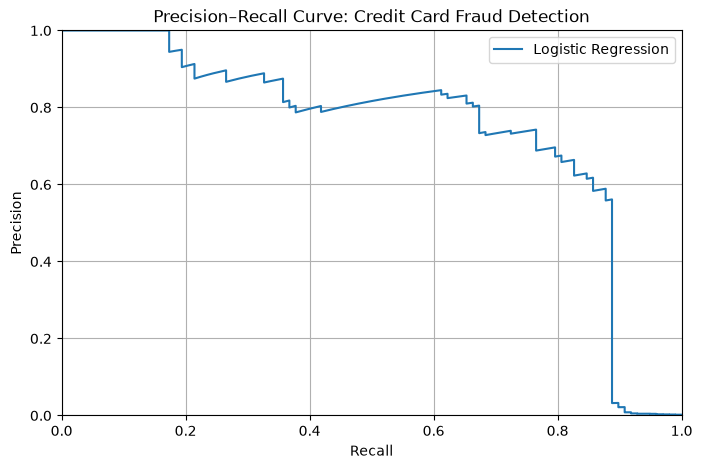

In [95]:
# Create a figure
plt.figure(figsize=(8, 5))

# Plot precision against recall
plt.plot(recall_values, precision_values,
         label="Logistic Regression")

# Label the axes
plt.xlabel("Recall")
plt.ylabel("Precision")

# Add a title
plt.title("Precision–Recall Curve: Credit Card Fraud Detection")

# Set axis limits
plt.xlim(0, 1)
plt.ylim(0, 1)

# Add a legend and grid
plt.legend()
plt.grid(True)

# Display the graph
plt.show()

### Stage 93 — Interpreting the Precision–Recall Curve

The precision–recall curve demonstrates how the model's precision
changes as recall increases.

Recall represents the proportion of actual fraudulent transactions
identified by the model.

Precision represents the proportion of fraud alerts that are correct.

As recall approaches 1, the model attempts to detect nearly all
fraudulent transactions.

However, detecting more fraud may require lowering the decision
threshold, potentially increasing the number of false positives.

This can reduce precision.

### What Does a Good Curve Look Like?

An effective classifier generally maintains high precision
across a wide range of recall values.

A curve that remains close to the upper-right region of the graph
indicates strong performance.

A curve that falls rapidly as recall increases indicates that
the model generates many false positives when attempting to
detect more fraudulent transactions.

> **Important:** The precision–recall curve is especially useful
> for imbalanced classification problems because it focuses on
> performance for the positive class, which in this project is fraud.

## 12. Average Precision

### Stage 94 — Summarising the Precision–Recall Curve

Although a precision–recall curve provides a useful visual
representation of model performance, it is often helpful to
summarise the curve using a single numerical value.

One such measure is **Average Precision (AP)**.

Average Precision summarises the precision–recall curve by
calculating a weighted average of precision values, where
the weights are determined by changes in recall.

Mathematically:

$$
AP = \sum_n (R_n - R_{n-1})P_n
$$

where:

- $P_n$ is precision at a particular point.
- $R_n$ is recall at that point.
- $R_n - R_{n-1}$ represents the increase in recall.

The calculation can be understood as adding together
contributions from different sections of the precision–recall
curve.

### Interpreting Average Precision

A higher Average Precision generally indicates that the
model is better at ranking fraudulent transactions above
legitimate transactions.

An AP close to 1 indicates very strong performance.

For an uninformative classifier, Average Precision is generally
close to the proportion of positive cases in the dataset.

In this project, the fraud prevalence is approximately:

$$
\frac{98}{56962} \approx 0.00172
$$

This provides a useful reference when interpreting the model's AP.

Average Precision is not necessarily identical to the area
calculated using trapezoidal integration of the curve.

In [96]:
from sklearn.metrics import average_precision_score

# Calculate Average Precision
ap = average_precision_score(y_test, y_prob)

# Display the result
print(f"Average Precision: {ap:.4f}")

# Display as a percentage
print(f"Average Precision: {ap:.2%}")

Average Precision: 0.7432
Average Precision: 74.32%


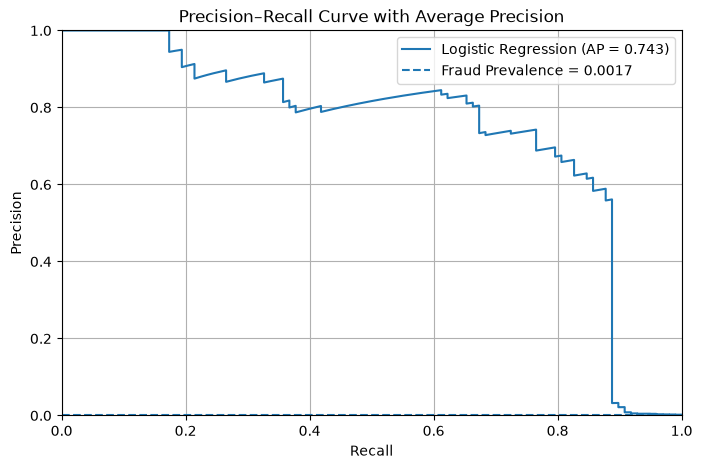

In [97]:
plt.figure(figsize=(8, 5))

# Plot precision-recall curve
plt.plot(
    recall_values,
    precision_values,
    label=f"Logistic Regression (AP = {ap:.3f})"
)

# Add a baseline representing fraud prevalence
fraud_prevalence = y_test.mean()

plt.axhline(
    y=fraud_prevalence,
    linestyle="--",
    label=f"Fraud Prevalence = {fraud_prevalence:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve with Average Precision")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(True)

plt.show()

### Interpretation of the Average Precision Graph

The graph now contains two reference elements.

**1. The Logistic Regression precision–recall curve**

This shows how precision changes as recall increases.

The legend also displays the Average Precision score,
which summarises the model's performance across thresholds.

**2. The fraud prevalence baseline**

The horizontal dashed line represents the proportion of
fraudulent transactions in the test dataset.

For this dataset, fraud represents approximately 0.172%
of transactions.

This is the expected precision of an uninformative
random-ranking classifier.

A model that produces a precision–recall curve substantially
above this baseline demonstrates an ability to distinguish
fraudulent transactions from legitimate ones.

## 13. Improving the Experimental Method

### Stage 95 — Training, Validation and Testing

During the initial investigation, different classification
thresholds were evaluated using the test dataset.

This was useful for understanding how the Logistic Regression
model behaves.

However, there is an important methodological limitation.

If the test dataset is repeatedly used to select thresholds
or optimise model settings, the final evaluation may become
biased towards that particular dataset.

This is a form of test-set leakage through model selection.

### A Better Experimental Design

A more rigorous approach separates the data into three
conceptual groups:

**1. Training Data**

Used to fit the machine-learning model and learn its
coefficients.

**2. Validation Data**

Used to compare models, tune hyperparameters and select
classification thresholds.

**3. Test Data**

Used only for the final evaluation after model development
has been completed.

The test dataset should remain unseen throughout model
development.

### Cross-Validation

Rather than reserving a single validation dataset,
cross-validation can repeatedly divide the training data
into different training and validation subsets.

This provides a more reliable estimate of model performance
during development.

For an imbalanced classification problem, stratified
cross-validation is particularly useful because it helps
preserve the proportion of fraudulent transactions
within each fold.

### Implications for This Project

The threshold experiments conducted so far should be treated
as exploratory investigations.

Before selecting the final model and reporting its performance,
I will establish a validation procedure using the training
data only.

The scaler must also be fitted separately within each
cross-validation training fold to avoid data leakage.

A completely untouched test dataset will then be used
for the final assessment.

> **Key methodological principle:** All model selection,
> threshold tuning and preprocessing decisions should be
> based on training and validation data, not the final test set.

### Stage 96 — Understanding ROC Curves

The **ROC curve** measures how well a classification model
distinguishes between two classes at different decision thresholds.

The two axes are:

- **True Positive Rate (TPR):** The proportion of actual fraud detected.
- **False Positive Rate (FPR):** The proportion of legitimate transactions incorrectly flagged.

The True Positive Rate is equivalent to recall:

$$
TPR = \frac{TP}{TP+FN}
$$

The False Positive Rate is:

$$
FPR = \frac{FP}{FP+TN}
$$

In [98]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate false positive and true positive rates
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate the area under the ROC curve
roc_auc = roc_auc_score(y_test, y_prob)

print(f"ROC AUC: {roc_auc:.4f}")

ROC AUC: 0.9559


## 14. Improving the Model with Class Weights

### Stage 96 — Why use class weights?

Our dataset contains far more legitimate transactions than fraudulent
transactions.

This creates a problem because the machine-learning model receives
many more examples of legitimate transactions during training.

One possible solution is to give the minority class greater importance
during training.

Scikit-learn provides the parameter:

`class_weight="balanced"`

This automatically assigns larger weights to classes containing fewer
observations.

The model is therefore penalised more heavily when it incorrectly
classifies an example from the minority class.

The objective is to improve fraud detection without removing any
training observations.

However, increased fraud recall may come at the expense of precision.

In [99]:
from sklearn.linear_model import LogisticRegression

# Create a new model using balanced class weights
balanced_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
balanced_model.fit(X_train_scaled, y_train)

print("Balanced model training complete.")

Balanced model training complete.


## 15. Comparing the Models

### Stage 97 — Cross-Validation

Cross-validation evaluates a model using several different
training and validation subsets.

For this experiment, I will use five-fold stratified
cross-validation.

The training dataset is divided into five parts.

Each part is used for validation once, while the remaining
four parts are used for training.

Stratification helps maintain the proportion of fraudulent
transactions in each fold.

This allows the original and balanced Logistic Regression
models to be compared without using the test dataset
to select the preferred model.

The preprocessing scaler is included inside a pipeline,
ensuring that it is fitted only on each training fold.

In [101]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Scale Time and Amount inside each cross-validation fold
preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), ["Time", "Amount"])
    ],
    remainder="passthrough"
)

# Create the two models
models = {
    "Original": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Balanced": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
}

# Five stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "ap": "average_precision"
        }
    )

    results.append({
        "Model": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "Average Precision": scores["test_ap"].mean()
    })

comparison = pd.DataFrame(results)

comparison.round(4)

,Model,Precision,Recall,F1,Average Precision
0,Original,0.8752,0.6421,0.7396,0.7622
1,Balanced,0.0629,0.9138,0.1177,0.7568


## 16. Final Model Selection

### Stage 98 — Selecting the Model

The original and balanced Logistic Regression models were compared
using five-fold stratified cross-validation.

The model with the highest mean F1 score will be selected.

The selected model will then be trained on the complete
training dataset.

Finally, it will be evaluated on the held-out test dataset.

The test results will be reported as a final assessment rather
than used to make further model-selection decisions.

Earlier test-set investigations were exploratory and are
not treated as an untouched final evaluation.

In [102]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)

# Select model using cross-validation F1
best_name = comparison.loc[
    comparison["F1"].idxmax(), "Model"
]

print("Selected model:", best_name)

# Create final pipeline
final_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", models[best_name])
])

# Fit on complete training dataset
final_model.fit(X_train, y_train)

# Evaluate on test dataset
final_predictions = final_model.predict(X_test)

final_probabilities = final_model.predict_proba(X_test)[:, 1]

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["Legitimate", "Fraud"]
))

print(
    "Average Precision:",
    round(average_precision_score(y_test, final_probabilities), 4)
)

Selected model: Original

Confusion Matrix:
[[56851    13]
 [   35    63]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962

Average Precision: 0.7432


## 17. Project Conclusion

### Aim

The aim of this project was to develop a machine-learning model
capable of identifying fraudulent credit-card transactions.

### What Was Achieved?

A Logistic Regression classifier was successfully trained using
a dataset containing 284,807 transactions.

The dataset was highly imbalanced, with fraudulent transactions
representing approximately 0.173% of the observations.

The original model achieved:

| Metric | Result |
|---|---:|
| Accuracy | 99.9157% |
| Precision | 82.8947% |
| Recall | 64.2857% |
| True Positives | 63 |
| False Negatives | 35 |

These results demonstrated that high classification accuracy
does not necessarily mean that a model detects most fraudulent
transactions.

### Further Investigation

Changing the classification threshold improved fraud recall,
but generally reduced precision.

A second Logistic Regression model was trained using balanced
class weights.

The two approaches were compared using stratified
cross-validation.

### Limitations

The dataset is highly imbalanced.

The PCA-transformed features cannot easily be interpreted
in terms of their original real-world meanings.

The model was developed using historical transactions,
and its performance on future transactions is unknown.

Some test-set results were examined during exploratory
development, limiting their independence as a final assessment.

### Final Reflection

This project demonstrates how data preparation, model training,
evaluation metrics and decision thresholds work together
in a binary classification problem.

It also illustrates why model performance must be interpreted
in relation to the problem being solved rather than relying
on accuracy alone.

## 18. Reproducibility and Project Documentation

This notebook documents an independent learning project
investigating credit-card fraud detection using Python
and scikit-learn.

The project was developed as part of a personal study of
machine learning, using published learning resources
as guidance.

All explanations, experiments and interpretations are
presented as original study notes.

### Software Libraries

- Python
- pandas
- NumPy
- Matplotlib
- scikit-learn
- JupyterLab

### Dataset

Credit Card Fraud Detection dataset, available from Kaggle:

https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

The dataset is not included in this repository.

Users should obtain the dataset from its original source
and follow the source's licensing and usage conditions.

### Reproducing the Experiment

1. Install the required Python libraries.
2. Download the dataset.
3. Place the CSV file in the expected data directory.
4. Open the notebook in JupyterLab.
5. Run the notebook cells in order.

### Future Development

Possible extensions include:

- Random Forest classification
- Undersampling and oversampling
- SMOTE
- Hyperparameter tuning
- Alternative decision thresholds
- Further cross-validation experiments

## 19. Comparing the Original and Balanced Models

### Stage 101 — Results of Cross-Validation

Two Logistic Regression models were compared using five-fold
stratified cross-validation.

The first model used the original class distribution.

The second model used `class_weight="balanced"` to give greater
importance to the minority (fraudulent) class during training.

### Cross-Validation Results

| Model | Precision | Recall | F1 Score | Average Precision |
|---|---:|---:|---:|---:|
| Original | 0.8752 | 0.6421 | 0.7396 | 0.7622 |
| Balanced | 0.0629 | 0.9138 | 0.1177 | 0.7568 |

### Interpretation

**Original Logistic Regression**

The original model achieved:

- Precision: 87.52%
- Recall: 64.21%
- F1 score: 73.96%

This model was relatively cautious about identifying fraud.

When it classified a transaction as fraudulent, it was usually
correct. However, it missed approximately 36% of the fraudulent
transactions during cross-validation.

**Balanced Logistic Regression**

The balanced model achieved:

- Precision: 6.29%
- Recall: 91.38%
- F1 score: 11.77%

The balanced model detected a much greater proportion of
fraudulent transactions.

However, its precision was extremely low.

A precision of 6.29% means that, on average, only approximately
6 out of every 100 fraud alerts were genuine.

The remaining alerts were false positives.

### Why Did This Happen?

The original dataset is extremely imbalanced.

The balanced model assigns greater importance to fraudulent
transactions during training.

This encourages the model to identify more transactions as
potentially fraudulent.

Although this improves recall, it also produces substantially
more false positives.

### Model Selection

The original model achieved the higher F1 score:

$$
F1_{\text{original}} = 0.7396
$$

$$
F1_{\text{balanced}} = 0.1177
$$

Therefore, the original Logistic Regression model was selected.

> **Key conclusion:** Improving recall does not necessarily improve
> the overall usefulness of a classifier. The consequences of
> false positives and false negatives must both be considered.

## 20. Final Model Evaluation

### Stage 102 — Results

The original Logistic Regression model was selected using
five-fold cross-validation.

The selected model was then fitted to the complete training
dataset and evaluated using the test dataset.

### Confusion Matrix

| Actual Class | Predicted Legitimate | Predicted Fraud |
|---|---:|---:|
| Legitimate | 56,851 | 13 |
| Fraud | 35 | 63 |

### Interpretation

The model correctly classified 56,851 legitimate transactions.

Only 13 legitimate transactions were incorrectly identified
as fraudulent.

Of the 98 actual fraudulent transactions:

- 63 were correctly identified.
- 35 were missed.

The model achieved approximately:

- Accuracy: 99.92%
- Fraud precision: 82.89%
- Fraud recall: 64.29%
- Fraud F1 score: 72.41%
- Average Precision: 0.7432

### Final Assessment

The original Logistic Regression model achieved a useful
balance between precision and recall at the default threshold.

However, approximately 36% of fraudulent transactions were
still missed.

The very high accuracy should not be interpreted as evidence
that the model detects almost all fraud.

The model's ability to detect fraud is better represented
by recall, precision and the F1 score.

### Limitations

The test dataset was previously examined during exploratory
threshold investigations. Consequently, these results should
not be described as a completely independent final evaluation.

The dataset is historical, and performance on future
transactions has not been established.

The PCA-transformed variables also limit our ability to
explain individual predictions in real-world terms.

### Conclusion

The experiment demonstrates that Logistic Regression can
identify patterns associated with fraudulent transactions.

It also demonstrates that class balancing is not automatically
beneficial.

The most appropriate model depends on the balance between
fraud detection, false alarms and the real-world consequences
of classification errors.